# Clasificación de arquitecturas de computadoras mediante la Taxonomía de Flynn

| Campo | Dato |
|---|---|
| **Institución** | Instituto Politécnico Nacional |
| **Unidad académica** | Escuela Superior de Cómputo (ESCOM) |
| **Ingeniería** | Ingeniería en Inteligencia Artificial |
| **Profesor** | Luis Alberto Ibañez Zamora |
| **Nombre completo** | Sergio Alejandro Vera Martínez |
| **Grupo** | 6BM2 |
| **Unidad de Aprendizaje** | Computo paralelo |
| **Unidad Temática** | I |
| **Nombre de la actividad** | Clasificación de arquitecturas de computadoras mediante la Taxonomía de Flynn |
| **Fecha de realización** | 30 de septiembre de 2026 |


## Objetivo

Analizar las cuatro arquitecturas propuestas en la Taxonomía de Flynn (SISD, SIMD, MISD y MIMD), identificando sus características, diferencias, funcionamiento y aplicaciones en sistemas de cómputo actuales mediante investigación, diagramas y ejercicios prácticos en Python.


---
# Parte 2. Investigación y análisis

## 1.3 Taxonomía de Flynn

**Origen.** La taxonomía fue propuesta por Michael J. Flynn en 1966 (y refinada en 1972) en una época en la que empezaban a aparecer máquinas con varias unidades de procesamiento. Flynn necesitaba un esquema sencillo para comparar organizaciones de computadoras sin depender de los detalles de cada fabricante.

**Propósito.** Dar un lenguaje común para describir *cómo* una máquina aprovecha (o no) el paralelismo, y así poder comparar arquitecturas muy distintas con las mismas categorías.

**Criterios de clasificación.** Flynn observa dos flujos que llegan a las unidades de procesamiento y pregunta cuántos hay de cada uno:

1. **Flujo de instrucciones (I):** la secuencia de instrucciones que se ejecuta. Puede ser *simple* (*Single*) o *múltiple* (*Multiple*).
2. **Flujo de datos (D):** la secuencia de datos sobre los que operan esas instrucciones. También *simple* o *múltiple*.

Al combinar ambos criterios salen cuatro categorías:

| | **Un flujo de datos** | **Varios flujos de datos** |
|---|---|---|
| **Un flujo de instrucciones** | SISD | SIMD |
| **Varios flujos de instrucciones** | MISD | MIMD |


In [1]:
# Funciones auxiliares para dibujar los diagramas de flujo de instrucciones (IS) y datos (DS)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

AZUL, VERDE, NARANJA, GRIS = "#cfe2ff", "#d1e7dd", "#ffe5b4", "#e9ecef"

def lienzo(titulo, w=10, h=7):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis("off")
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    return fig, ax

def caja(ax, x, y, w, h, txt, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="black"))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=9)

def flecha(ax, p1, p2, txt="", color="black", dx=0.1):
    ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="->", color=color, lw=1.6))
    if txt:
        ax.text((p1[0]+p2[0])/2 + dx, (p1[1]+p2[1])/2, txt, fontsize=8, color=color)

def leyenda(ax, x=0.1, y=0.1):
    ax.text(x, y, "Azul: flujo de instrucciones (IS)   |   Naranja: flujo de datos (DS)", fontsize=8)


## 1.3.1 SISD (Single Instruction, Single Data)

**Características.** Hay una sola unidad de control que emite un único flujo de instrucciones y una sola unidad de procesamiento que trabaja con un único flujo de datos. En cada instante se ejecuta una instrucción sobre un dato. Es el modelo secuencial clásico (von Neumann); el paralelismo, si existe, es solo interno (por ejemplo, segmentación o *pipeline*, que sigue manteniendo un flujo lógico de instrucciones).

**Funcionamiento.** La unidad de control toma la siguiente instrucción de memoria, la decodifica, la unidad de procesamiento la ejecuta con un operando, se guarda el resultado y se pasa a la siguiente instrucción.

**Ejemplo de aplicación.** Computadoras personales antiguas, microcontroladores sencillos y programas secuenciales tradicionales: una calculadora básica, un script que recorre una lista elemento por elemento.


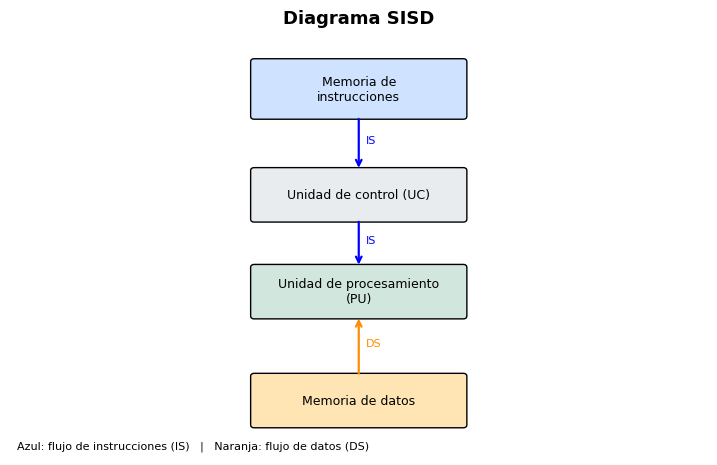

In [2]:
fig, ax = lienzo("Diagrama SISD")
caja(ax, 3.5, 5.6, 3, 0.9, "Memoria de\ninstrucciones", AZUL)
caja(ax, 3.5, 3.9, 3, 0.8, "Unidad de control (UC)", GRIS)
caja(ax, 3.5, 2.3, 3, 0.8, "Unidad de procesamiento\n(PU)", VERDE)
caja(ax, 3.5, 0.5, 3, 0.8, "Memoria de datos", NARANJA)
flecha(ax, (5, 5.6), (5, 4.7), "IS", "blue")
flecha(ax, (5, 3.9), (5, 3.1), "IS", "blue")
flecha(ax, (5, 1.3), (5, 2.3), "DS", "darkorange")
leyenda(ax)
plt.show()


## 1.3.2 SIMD (Single Instruction, Multiple Data)

**Características.** Una única unidad de control envía **la misma instrucción** a varias unidades de procesamiento, y cada una la aplica a **un dato distinto**. Las unidades trabajan en sincronía (*lock-step*). Funciona muy bien cuando el problema es regular: la misma operación repetida sobre muchos elementos.

**Procesamiento vectorial.** En lugar de sumar número por número, el procesador carga un vector (varios elementos en un registro ancho) y ejecuta una sola instrucción que opera sobre todos sus elementos a la vez. Ejemplos reales son las extensiones SSE/AVX en procesadores x86 y NEON en ARM.

**Aplicaciones en GPU.** Las GPU tienen miles de núcleos pequeños agrupados para ejecutar la misma instrucción sobre muchos elementos (en NVIDIA, el modelo se llama SIMT, una variante de SIMD). Por eso destacan en gráficos (cada píxel o vértice recibe el mismo tratamiento), procesamiento de imágenes y multiplicación de matrices para aprendizaje automático.


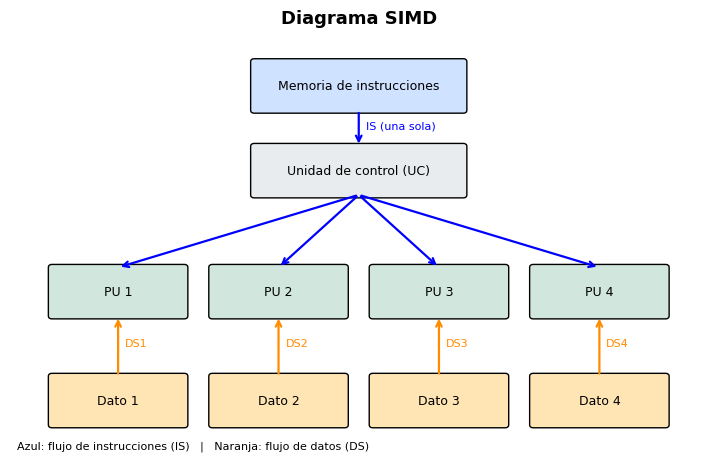

In [3]:
fig, ax = lienzo("Diagrama SIMD")
caja(ax, 3.5, 5.7, 3, 0.8, "Memoria de instrucciones", AZUL)
caja(ax, 3.5, 4.3, 3, 0.8, "Unidad de control (UC)", GRIS)
xs = [0.6, 2.9, 5.2, 7.5]
for i, x in enumerate(xs, start=1):
    caja(ax, x, 2.3, 1.9, 0.8, f"PU {i}", VERDE)
    caja(ax, x, 0.5, 1.9, 0.8, f"Dato {i}", NARANJA)
    flecha(ax, (5, 4.3), (x + 0.95, 3.1), "", "blue")
    flecha(ax, (x + 0.95, 1.3), (x + 0.95, 2.3), f"DS{i}", "darkorange")
flecha(ax, (5, 5.7), (5, 5.1), "IS (una sola)", "blue")
leyenda(ax)
plt.show()


## 1.3.3 MISD (Multiple Instruction, Single Data)

**Principio de funcionamiento.** Varias unidades de procesamiento, cada una con **su propio flujo de instrucciones**, operan sobre **el mismo flujo de datos**. El dato pasa por las unidades (o se les entrega a todas) y cada una le aplica una operación distinta.

**Dificultades de implementación.** Son pocos los problemas reales que se benefician de aplicar instrucciones diferentes al mismo dato al mismo tiempo; casi siempre resulta mejor un *pipeline* o una máquina MIMD. Además, exige sincronizar con cuidado las unidades y es difícil de programar, por lo que no hay hardware MISD comercial de propósito general.

**Posibles aplicaciones.** Sistemas tolerantes a fallos donde varias unidades procesan la misma entrada con programas distintos y se comparan resultados (por ejemplo, las computadoras de control de vuelo con redundancia y votación), y algunos arreglos sistólicos o de filtrado que procesan un mismo flujo de señal con distintas operaciones. La clasificación de estos últimos casos como MISD es discutida.


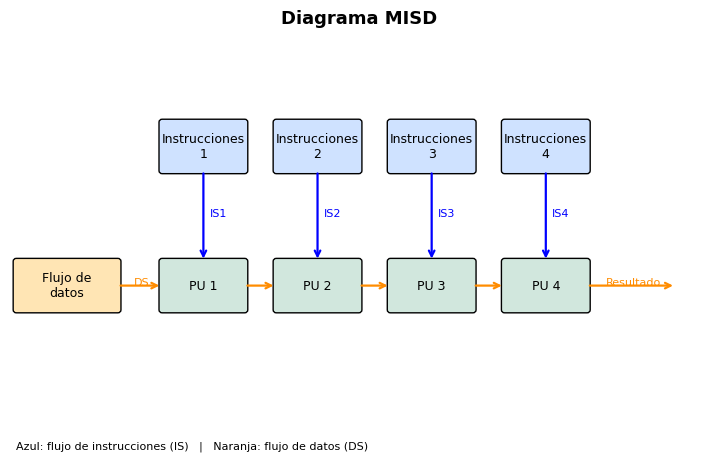

In [4]:
fig, ax = lienzo("Diagrama MISD", w=11)
xs = [2.4, 4.2, 6.0, 7.8]
caja(ax, 0.1, 2.4, 1.6, 0.8, "Flujo de\ndatos", NARANJA)
for i, x in enumerate(xs, start=1):
    caja(ax, x, 2.4, 1.3, 0.8, f"PU {i}", VERDE)
    caja(ax, x, 4.7, 1.3, 0.8, f"Instrucciones\n{i}", AZUL)
    flecha(ax, (x + 0.65, 4.7), (x + 0.65, 3.2), f"IS{i}", "blue")
flecha(ax, (1.7, 2.8), (2.4, 2.8), "DS", "darkorange", dx=-0.1)
for x in xs[:-1]:
    flecha(ax, (x + 1.3, 2.8), (x + 1.8, 2.8), "", "darkorange")
flecha(ax, (9.1, 2.8), (10.5, 2.8), "Resultado", "darkorange", dx=-0.4)
leyenda(ax)
plt.show()


## 1.3.4 MIMD (Multiple Instruction, Multiple Data)

**Procesamiento independiente.** Cada unidad de procesamiento tiene su propio flujo de instrucciones y trabaja con sus propios datos, de forma asíncrona. Pueden ejecutar programas totalmente distintos o el mismo programa sobre datos diferentes, sin esperar a que los demás avancen.

**Multiprocesadores.** Varios procesadores comparten una memoria común (memoria compartida); se comunican leyendo y escribiendo en ella y necesitan mecanismos de sincronización (candados, semáforos) para evitar condiciones de carrera. Existe también la variante de **multicomputadores** o clústeres, con memoria distribuida y comunicación por mensajes (MPI).

**Sistemas multinúcleo.** Un procesador multinúcleo integra varios núcleos en un mismo chip, y cada núcleo puede ejecutar su propio hilo o proceso. Es la forma más extendida de MIMD: laptops, teléfonos y servidores actuales.


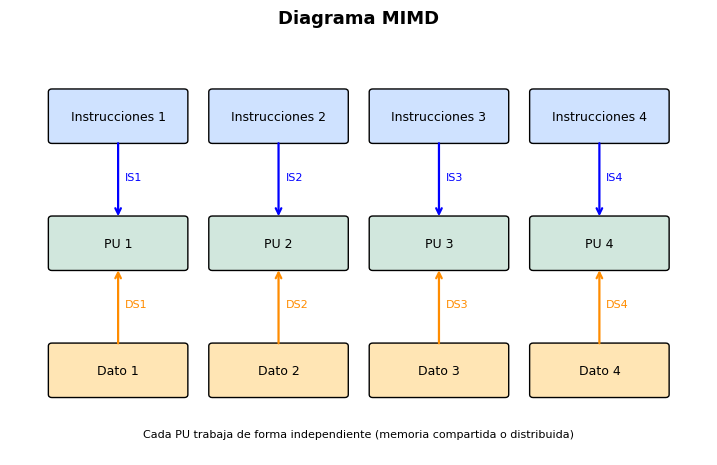

In [5]:
fig, ax = lienzo("Diagrama MIMD")
xs = [0.6, 2.9, 5.2, 7.5]
for i, x in enumerate(xs, start=1):
    caja(ax, x, 5.2, 1.9, 0.8, f"Instrucciones {i}", AZUL)
    caja(ax, x, 3.1, 1.9, 0.8, f"PU {i}", VERDE)
    caja(ax, x, 1.0, 1.9, 0.8, f"Dato {i}", NARANJA)
    flecha(ax, (x + 0.95, 5.2), (x + 0.95, 3.9), f"IS{i}", "blue")
    flecha(ax, (x + 0.95, 1.8), (x + 0.95, 3.1), f"DS{i}", "darkorange")
ax.text(5, 0.3, "Cada PU trabaja de forma independiente (memoria compartida o distribuida)", ha="center", fontsize=8)
plt.show()


## 1.3.5 Aplicaciones actuales

| Arquitectura | Ejemplos actuales |
|---|---|
| **SISD** | Microcontroladores simples (termostatos, electrodomésticos), programas secuenciales y núcleos individuales ejecutando código escalar. |
| **SIMD** | Extensiones vectoriales AVX/SSE y NEON en CPU; GPU para renderizado, procesamiento de imágenes y video, y multiplicación de matrices en redes neuronales; librerías como NumPy que aprovechan instrucciones vectoriales. |
| **MISD** | Sistemas de control críticos con redundancia y votación (aeronáutica, espacial); ciertos arreglos sistólicos de procesamiento de señales. Es la categoría menos usada. |
| **MIMD** | Procesadores multinúcleo de PC y celulares, servidores web, bases de datos, supercomputadoras y clústeres en la nube, sistemas operativos multitarea. |

En la práctica, los sistemas modernos **combinan** varias categorías: un servidor con varios núcleos (MIMD), donde cada núcleo usa unidades vectoriales (SIMD), y que además aloja GPU (SIMD/SIMT).


---
# Parte 3. Experimentación en Google Colab

## Ejercicio 1. SISD

Se procesa secuencialmente una lista de 100 números y se calcula el cuadrado de cada elemento con un ciclo `for`. Cada iteración ejecuta una instrucción sobre un dato.


In [6]:
import random

random.seed(42)  # semilla fija para reproducibilidad
numeros = [random.randint(1, 100) for _ in range(100)]

cuadrados_sisd = []
for x in numeros:                # un elemento a la vez
    cuadrados_sisd.append(x ** 2)

print("Primeros 10 números :", numeros[:10])
print("Sus cuadrados (SISD):", cuadrados_sisd[:10])
print("Total de elementos  :", len(cuadrados_sisd))


Primeros 10 números : [82, 15, 4, 95, 36, 32, 29, 18, 95, 14]
Sus cuadrados (SISD): [6724, 225, 16, 9025, 1296, 1024, 841, 324, 9025, 196]
Total de elementos  : 100


## Ejercicio 2. SIMD

Misma operación con NumPy, sin ciclos explícitos, y comparación con el ejercicio anterior.

In [7]:
import numpy as np

arreglo = np.array(numeros)
cuadrados_simd = arreglo ** 2     # operación vectorizada, sin ciclo explícito

print("Cuadrados (NumPy):", cuadrados_simd[:10])
print("¿Resultados idénticos a SISD?:", np.array_equal(cuadrados_simd, np.array(cuadrados_sisd)))


Cuadrados (NumPy): [6724  225   16 9025 1296 1024  841  324 9025  196]
¿Resultados idénticos a SISD?: True


Ciclo for (SISD)     : 86.93 ms
NumPy vectorizado    : 1.83 ms
NumPy fue 47.5 veces más rápido


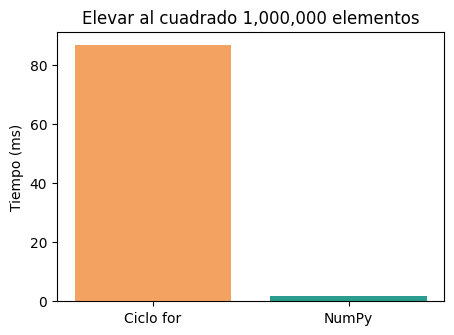

In [8]:
# Comparación de tiempos con un conjunto más grande (con 100 elementos la diferencia es difícil de medir)
import time

N = 1_000_000
grande_lista = list(range(N))
grande_np = np.arange(N)

def medir(f, repeticiones=5):
    mejor = float("inf")
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        f()
        mejor = min(mejor, time.perf_counter() - t0)
    return mejor

def con_ciclo():
    r = []
    for x in grande_lista:
        r.append(x ** 2)
    return r

t_ciclo = medir(con_ciclo)
t_numpy = medir(lambda: grande_np ** 2)

print(f"Ciclo for (SISD)     : {t_ciclo*1000:.2f} ms")
print(f"NumPy vectorizado    : {t_numpy*1000:.2f} ms")
print(f"NumPy fue {t_ciclo/t_numpy:.1f} veces más rápido")

plt.figure(figsize=(5, 3.5))
plt.bar(["Ciclo for", "NumPy"], [t_ciclo*1000, t_numpy*1000], color=["#f4a261", "#2a9d8f"])
plt.ylabel("Tiempo (ms)")
plt.title(f"Elevar al cuadrado {N:,} elementos")
plt.show()


**Interpretación.** Ambos métodos producen exactamente los mismos resultados, pero NumPy es considerablemente más rápido al trabajar con muchos datos. El ciclo `for` ejecuta código de Python elemento por elemento (estilo SISD), mientras que NumPy delega la operación completa a rutinas compiladas en C que recorren el arreglo en bloques contiguos y pueden apoyarse en instrucciones vectoriales (SIMD) del procesador. Por esa razón, parte de la ventaja se debe a evitar el costo del intérprete y no solo al SIMD.

Como advierte la nota de la actividad, en Colab (un entorno virtualizado) no podemos garantizar que se usen físicamente instrucciones SIMD; el ejercicio sirve para entender el concepto de *una operación sobre muchos datos*.


## Ejercicio 3. MISD (representación conceptual)

Un mismo conjunto de datos se procesa con tres operaciones distintas: media, desviación estándar y valor máximo.

In [9]:
np.random.seed(7)
datos = np.random.normal(loc=50, scale=10, size=1000)   # un único flujo de datos

operaciones = {
    "Media": np.mean,
    "Desviación estándar": np.std,
    "Valor máximo": np.max,
}

for nombre, instruccion in operaciones.items():   # tres "instrucciones" distintas, mismo dato
    print(f"{nombre:<20}: {instruccion(datos):.4f}")


Media               : 49.7152
Desviación estándar : 9.6246
Valor máximo        : 78.6107


**Explicación.** Este programa ilustra el concepto de MISD porque **tres operaciones distintas (instrucciones diferentes) se aplican sobre el mismo conjunto de datos**: hay varios flujos de instrucciones y un solo flujo de datos.

Sin embargo, **no es necesariamente una implementación MISD real**, por estas razones:

- Las tres operaciones se ejecutan una después de otra en un solo procesador (comportamiento SISD); no hay tres unidades de procesamiento trabajando a la vez sobre el dato.
- En un MISD real, el dato fluiría por varias unidades físicas independientes, cada una con su propia unidad de control y su propio programa.
- La separación en funciones es una organización del software, no del hardware.

Por eso se trata de una representación *conceptual* del modelo.


## Ejercicio 4. MIMD

El módulo `multiprocessing` de Python permite crear procesos del sistema operativo con su propio espacio de memoria e intérprete. La clase `Process` recibe una función objetivo (`target`) y sus argumentos (`args`); con `start()` se lanza el proceso y con `join()` se espera a que termine. Como los procesos no comparten memoria, los resultados se devuelven mediante un `Queue`.

Aquí dos procesos ejecutan **funciones distintas** con **conjuntos de datos diferentes**:

- **Proceso A:** suma de cuadrados de una lista de 3 millones de enteros.
- **Proceso B:** cuenta cuántos números primos hay en una lista de 20,000 enteros aleatorios.


In [10]:
import multiprocessing as mp
import os, time

def suma_de_cuadrados(datos, cola):
    inicio = time.time()
    resultado = sum(x * x for x in datos)
    fin = time.time()
    cola.put(("Proceso A (suma de cuadrados)", os.getpid(), resultado, inicio, fin))

def es_primo(n):
    if n < 2:
        return False
    i = 2
    while i * i <= n:
        if n % i == 0:
            return False
        i += 1
    return True

def contar_primos(datos, cola):
    inicio = time.time()
    resultado = sum(1 for x in datos if es_primo(x))
    fin = time.time()
    cola.put(("Proceso B (conteo de primos)", os.getpid(), resultado, inicio, fin))

lista_a = list(range(1, 3_000_001))
random.seed(1)
lista_b = [random.randint(1, 1_000_000) for _ in range(20_000)]

print("PID del proceso principal:", os.getpid())
print("Núcleos de CPU disponibles:", os.cpu_count())

cola = mp.Queue()
pa = mp.Process(target=suma_de_cuadrados, args=(lista_a, cola))
pb = mp.Process(target=contar_primos, args=(lista_b, cola))

t0 = time.time()
pa.start(); pb.start()
resultados = [cola.get(), cola.get()]   # se recogen antes del join
pa.join(); pb.join()
t_paralelo = time.time() - t0

print("\n--- Resultados ---")
for nombre, pid, res, ini, fin in sorted(resultados):
    print(f"{nombre}: PID={pid}, resultado={res}, duración={fin-ini:.3f} s, "
          f"inicio={ini-t0:.3f} s, fin={fin-t0:.3f} s (respecto al lanzamiento)")
print(f"\nTiempo total con procesos: {t_paralelo:.3f} s")


PID del proceso principal: 148
Núcleos de CPU disponibles: 1



--- Resultados ---
Proceso A (suma de cuadrados): PID=170, resultado=9000004500000500000, duración=0.441 s, inicio=0.015 s, fin=0.456 s (respecto al lanzamiento)
Proceso B (conteo de primos): PID=171, resultado=1491, duración=0.242 s, inicio=0.024 s, fin=0.266 s (respecto al lanzamiento)

Tiempo total con procesos: 0.465 s


In [11]:
# Referencia: las mismas dos tareas ejecutadas una tras otra en el proceso principal
from queue import Queue
q = Queue()
t0 = time.time()
suma_de_cuadrados(lista_a, q)
contar_primos(lista_b, q)
t_secuencial = time.time() - t0

print(f"Tiempo secuencial : {t_secuencial:.3f} s")
print(f"Tiempo con procesos: {t_paralelo:.3f} s")
print(f"Relación secuencial / procesos: {t_secuencial / t_paralelo:.2f}")


Tiempo secuencial : 0.391 s
Tiempo con procesos: 0.465 s
Relación secuencial / procesos: 0.84


**Interpretación de resultados.**

- Los dos procesos tienen **PID distintos** entre sí y distintos del proceso principal: son flujos de ejecución independientes, cada uno con su propio programa (función) y sus propios datos, lo que corresponde al modelo **MIMD**.
- Si los intervalos de inicio y fin de ambos procesos se **traslapan**, indica que se ejecutaron de forma concurrente, y el tiempo total se acerca al de la tarea más larga en lugar de la suma de ambas. Cuántas veces se acelera depende de cuántos núcleos reales tenga asignados la máquina virtual de Colab (normalmente pocos).
- Como indica la nota de la actividad, este ejemplo **no demuestra por sí solo paralelismo efectivo**: Colab es un entorno virtualizado, el sistema operativo puede planificar los procesos de forma intercalada en un solo núcleo, y crear procesos tiene un costo adicional. Aun así, permite analizar conceptualmente cómo funciona una arquitectura MIMD.


---
# Parte 4. Cuadro comparativo

| Característica | **SISD** | **SIMD** | **MISD** | **MIMD** |
|---|---|---|---|---|
| **Flujos de instrucciones** | 1 | 1 | Múltiples | Múltiples |
| **Flujos de datos** | 1 | Múltiples | 1 | Múltiples |
| **Características principales** | Una unidad de control y una de procesamiento; ejecución secuencial. | Una unidad de control que difunde la misma instrucción a varias unidades que operan en sincronía. | Varias unidades con programas distintos procesan el mismo flujo de datos. | Varios procesadores autónomos, cada uno con su programa y sus datos; ejecución asíncrona. |
| **Ventajas** | Sencillo de diseñar, programar y depurar; bajo costo. | Muy eficiente en operaciones regulares sobre grandes volúmenes de datos; poca lógica de control. | Redundancia y tolerancia a fallos; posibilidad de comparar resultados. | Gran flexibilidad; escala bien; admite tareas heterogéneas y distintos tipos de paralelismo. |
| **Limitaciones** | Sin paralelismo explícito; el rendimiento depende de la velocidad del reloj. | Poco eficiente con código con muchas ramificaciones o datos irregulares. | Muy pocas aplicaciones reales; difícil de programar y sincronizar. | Programación compleja (sincronización, condiciones de carrera, comunicación); mayor costo y consumo. |
| **Ejemplo de hardware o sistema** | Microcontrolador simple; PC antigua con un solo núcleo. | Extensiones AVX/SSE/NEON; GPU (modelo SIMT). | Computadoras de control de vuelo redundantes; arreglos sistólicos (caso discutido). | CPU multinúcleo; clústeres y supercomputadoras. |
| **Aplicación práctica** | Programas secuenciales, control de electrodomésticos. | Procesamiento de imágenes, gráficos 3D, multiplicación de matrices. | Sistemas críticos con votación de resultados. | Servidores, sistemas operativos multitarea, cómputo en la nube. |


---
# Parte 5. Cuestionario de análisis

**1. ¿Qué criterios utiliza Flynn para clasificar las arquitecturas?**

Flynn usa dos criterios: el número de **flujos de instrucciones** y el número de **flujos de datos** que maneja el sistema, cada uno puede ser simple o múltiple. Al combinarlos se obtienen SISD, SIMD, MISD y MIMD. Es importante que clasifica según el comportamiento visto desde el procesador y no según detalles físicos de construcción.

**2. ¿Cuál es la principal diferencia entre SISD y SIMD?**

En SISD una instrucción opera sobre un solo dato por vez; en SIMD la misma instrucción opera sobre varios datos al mismo tiempo. Por ejemplo, para sumar 8 pares de números, SISD necesita 8 instrucciones de suma, mientras que SIMD puede hacerlo con una sola instrucción vectorial.

**3. ¿Por qué una GPU puede resultar eficiente al ejecutar determinadas operaciones sobre grandes conjuntos de datos?**

Porque tiene miles de núcleos simples que aplican la misma operación a muchos elementos a la vez (modelo SIMD/SIMT), y cuenta con un gran ancho de banda de memoria. Cuando los datos son independientes entre sí y la operación es uniforme, como procesar píxeles o multiplicar matrices, casi todos los núcleos trabajan de forma útil al mismo tiempo. Pierde eficiencia si hay muchas ramificaciones o dependencias entre datos.

**4. ¿Cuál es la diferencia entre SIMD y MIMD?**

En SIMD hay un único flujo de instrucciones compartido y todas las unidades ejecutan la misma instrucción en sincronía, sobre datos distintos. En MIMD cada procesador tiene su propio flujo de instrucciones y puede ejecutar programas diferentes de forma asíncrona. SIMD es más eficiente en problemas regulares; MIMD es más flexible pero exige más sincronización.

**5. ¿Por qué MISD es una arquitectura poco común?**

Porque pocos problemas requieren aplicar, al mismo tiempo, operaciones distintas a exactamente el mismo dato, y cuando se necesita, suele resolverse mejor con un pipeline o con MIMD. Además, es difícil de programar y sincronizar. Su uso se limita sobre todo a sistemas tolerantes a fallos con redundancia, donde varios módulos procesan la misma entrada y se comparan resultados.

**6. ¿Una computadora con procesador multinúcleo puede ejecutar instrucciones de tipo SIMD? Justifica.**

Sí. A nivel de núcleos, un procesador multinúcleo es MIMD porque cada núcleo ejecuta su propio hilo. Pero además cada núcleo suele incluir unidades vectoriales (SSE, AVX, NEON) que ejecutan instrucciones SIMD sobre varios datos de un registro. Es decir, ambos modelos conviven en el mismo chip.

**7. ¿Cuál de las arquitecturas permite que diferentes procesadores ejecuten programas independientes sobre datos distintos?**

MIMD, porque cada procesador dispone de su propio flujo de instrucciones y de su propio flujo de datos, y no tienen que avanzar de forma sincronizada.

**8. ¿Qué relación existe entre la Taxonomía de Flynn y el concepto de paralelismo?**

La taxonomía clasifica las arquitecturas según el tipo de paralelismo que explotan. SISD no tiene paralelismo entre flujos; SIMD explota el **paralelismo de datos** (misma operación sobre muchos datos); MIMD explota el **paralelismo de tareas o hilos** (programas distintos al mismo tiempo); MISD se asocia a varias operaciones sobre un mismo dato, principalmente con fines de redundancia. Así, la taxonomía sirve como marco para describir cómo se logra la ejecución simultánea.

**9. ¿En qué categoría ubicarías un clúster de computadoras donde cada nodo ejecuta tareas independientes? Explica.**

En **MIMD**, específicamente como un multicomputador de memoria distribuida. Cada nodo tiene su propio procesador, memoria y programa, procesa sus propios datos y se comunica con los demás mediante la red (por ejemplo, con MPI). Internamente, cada nodo puede ser multinúcleo y usar unidades SIMD, pero el clúster en conjunto es MIMD.

**10. ¿Qué arquitectura o combinación de arquitecturas consideras adecuada para entrenar un modelo de inteligencia artificial? Fundamenta tu respuesta.**

Una **combinación de SIMD y MIMD**. El entrenamiento se basa en multiplicaciones de matrices y operaciones tensoriales repetidas sobre enormes cantidades de datos, que encajan muy bien en SIMD/SIMT, por eso se usan GPU o aceleradores como las TPU. Para escalar, se usan varias GPU y varios nodos trabajando en paralelo (paralelismo de datos o de modelo), lo cual es MIMD a nivel de sistema. La CPU, que actúa como SISD/MIMD, se encarga de la preparación de datos y del control del flujo de entrenamiento.


---
# Conclusiones personales

- La Taxonomía de Flynn es simple, pero permite ubicar rápidamente qué tipo de paralelismo aprovecha un sistema; me ayudó a ver que conceptos como "vectorizar" o "usar varios procesos" corresponden a modelos de hardware concretos.
- En el ejercicio SIMD vi que NumPy supera claramente a un ciclo `for` cuando hay muchos datos, aunque entendí que parte de esa ventaja viene de evitar el costo del intérprete de Python y no solo de las instrucciones vectoriales.
- En MISD comprendí la diferencia entre *representar un concepto con software* y *tener la arquitectura real*: mi programa aplicaba tres operaciones al mismo dato, pero de manera secuencial.
- En MIMD observé procesos con PID distintos ejecutando funciones diferentes; sin embargo, en un entorno virtualizado como Colab no puedo asegurar paralelismo físico real, solo analizarlo de manera conceptual.
- Para inteligencia artificial, que es mi carrera, resulta evidente que el entrenamiento de modelos depende de la combinación de SIMD (GPU) y MIMD (múltiples dispositivos y nodos).

---
# Referencias

1. Flynn, M. J. (1966). Very high-speed computing systems. *Proceedings of the IEEE, 54*(12), 1901-1909.
2. Flynn, M. J. (1972). Some computer organizations and their effectiveness. *IEEE Transactions on Computers, C-21*(9), 948-960.
3. Stallings, W. (2016). *Computer Organization and Architecture: Designing for Performance* (10.ª ed.). Pearson.
4. Hennessy, J. L. y Patterson, D. A. (2017). *Computer Architecture: A Quantitative Approach* (6.ª ed.). Morgan Kaufmann.
5. Python Software Foundation. *multiprocessing — Process-based parallelism*. Documentación de Python 3. https://docs.python.org/3/library/multiprocessing.html
6. NumPy Developers. *NumPy documentation*. https://numpy.org/doc/
